# Creating the ToR checklist
To create the **ToR checklist**, I first scan all .docx files, extract the document text plus each review comment with its anchor paragraph and section/heading context, then clean and anonymise the extracted content. Afterwards, I group the data by section and send batches of (anchor + comment) pairs to the OpenAI model. The model validates the checklist items, removes duplications, rank items by priority and evidence, cap the number of items per section and export the final checklist to a CSV.

## 1 Installations, imports and paths

In [ ]:
# Cell 1.1 — Install required libraries and download NLP model

# Install required Python libraries for data processing, text cleaning, NLP, environment handling, and OpenAI API access
!pip install pandas spacy ftfy python-dotenv openai

# Download the multilingual spaCy model used for named entity recognition (e.g., anonymizing person names)
!python -m spacy download xx_ent_wiki_sm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 955.6 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 54.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('xx_ent_wiki_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# Cell 1.2 — Import libraries grouped by function (standard, data, NLP, API, visualization)

# Standard library (file handling, regex, XML parsing, typing, JSON)
import os
import re
import json
import zipfile
import textwrap
import xml.etree.ElementTree as ET
from typing import List, Literal

# Data handling
import pandas as pd

# Natural language processing and text cleaning
import spacy
from ftfy import fix_text

# Environment and API access
from dotenv import load_dotenv
from openai import OpenAI
from pydantic import BaseModel, Field

# Visualization
import matplotlib.pyplot as plt

In [ ]:
# Cell 1.3 — Mount Google Drive to access project files

# Import Colab drive module and mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Cell 1.4 — Define file and directory paths used in the project

# Directory containing the commented ToR .docx files
SECO_TOR_DIR = "/content/drive/MyDrive/HSLU/Masters_Thesis/Checklist_Documents/SECO_ToRs_Commented_No_Track"

# Path to the cleaned comments CSV generated earlier in the pipeline
CLEANED_COMMENTS_CSV_PATH = os.path.join(
    "/content/drive/MyDrive/HSLU/Masters_Thesis/Checklist_Documents",
    "ToR_comments_table_clean.csv",
)

# Path to the environment file storing API keys and secrets
ENV_FILE_PATH = "/content/drive/MyDrive/HSLU/Masters_Thesis/.env"

# Output directory for the final generated checklist
CHECKLIST_OUT_DIR = "/content/drive/MyDrive/HSLU/Masters_Thesis/Checklist_Documents"

# Full path to the exported checklist CSV file
CHECKLIST_OUT_PATH = os.path.join(CHECKLIST_OUT_DIR, "tor_checklist.csv")

In [ ]:
# Cell 2 — Identify and preview input ToR documents

# List all .docx files in the input directory
files = [f for f in os.listdir(SECO_TOR_DIR) if f.lower().endswith(".docx")]

# Print total number of ToR files found
print("Found files:", len(files))

# Display full list of detected files
files[:]


Found files: 36


['33_2025 PEFA Impact Evaluation ToR_Nov222025 SECO.docx',
 '5_Evaluation Protocol v0.2.docx',
 '20_SIFEM_TAF_Evaluation_ToR_Draft_comments.docx',
 '45_ToR ZPE CIMO PN_2020.2229.1 comm SECO_2025_06_10_mcn.docx',
 '37_FSDRP II - external project evaluation terms of reference SECO Comments WB.docx',
 '43_F4D Umbrella_MTR_TOR_DRAFT for discussion_mcn.docx',
 '49_RFU Mid-term evaluation TOR _draft_July2025_mcn.docx',
 '25_TOR_ SEE III_Draft Nov2024_External ESC_feedback-mcn.docx',
 '58_IPDP external project evaluation ToR_08.12.2025_mcn.docx',
 '24_TOR Evaluation_IFSSP III_2024 v1b clean.docx',
 '40_ToR Evaluation EEA Projects AL _SE_mcn.docx',
 '27_Draft TOR_independent ev_12.05.2024_mcn.docx',
 '47_SQARP - ToR Evaluation Draft_mcnV3.docx',
 '29_V1_Draft TOR MTE SIFI_mcn.docx',
 '56_Draft TOR MTR MCICP II_mcn.docx',
 '55_PE4DW final evaluation ToR_mcn.docx',
 '17_SCORE Phase IV final evaluation ToR_28June2024_mcn.docx',
 "53_DT4PAG_evaluation_TOR SECO's comments_mcn.docx",
 '52_ToR_Evalua

## 2 Extracting comments from ToRs, cleaning and saving them

In [ ]:
# Cell 2.1 — Define SECO ToR section buckets and keyword-based classification rules

# Predefined SECO ToR sections used for categorizing comment-anchor pairs
SECO_BUCKETS = [
    "1. Purpose of the Evaluation",
    "2. Description of the Intervention",
    "3. Scope and Focus of the Evaluation / Evaluation Questions",
    "4. Evaluation Methods and Process",
    "5. Deliverables",
    "6. Schedule",
    "7. Evaluation Team / Qualifications",
    "8. Budget",
    "9. Annexes",
]

# Fallback category if no keyword match is found
UNKNOWN_BUCKET = "(unknown)"

# Keyword mapping used for lightweight rule-based bucket assignment
# If keywords appear in heading/anchor/comment text, the corresponding bucket gains a score
BUCKET_KEYWORDS = {
    "1. Purpose of the Evaluation": [
        "purpose","objective","aim","goal","intended use","intended user","primary","secondary","learning","accountability"
    ],
    "2. Description of the Intervention": [
        "intervention","programme","program","project","background","context","stakeholder","theory of change","toc",
        "logframe","results framework","assumption","causal","rationale"
    ],
    "3. Scope and Focus of the Evaluation / Evaluation Questions": [
        "scope","focus","evaluation question","evaluation questions","key questions","questions","criteria","dac","oecd",
        "coverage","in scope","out of scope"
    ],
    "4. Evaluation Methods and Process": [
        "method","methods","methodology","approach","design","sampling","sample","data collection","interview","survey",
        "focus group","analysis","triangulation","ethics","limitations","validation workshop","matrix"
    ],
    "5. Deliverables": [
        "deliverable","deliverables","output","outputs","report","reporting","inception report","draft report","final report",
        "presentation","briefing","workshop note","quality assurance","publication","confidential","privacy","annexed report"
    ],
    "6. Schedule": [
        "schedule","timeline","time plan","workplan","work plan","milestone","deadline","date","week","calendar","duration"
    ],
    "7. Evaluation Team / Qualifications": [
        "team","qualifications","expertise","experience","cv","competence","skills","team leader","evaluator","consultant"
    ],
    "8. Budget": [
        "budget","cost","costs","financial","fee","fees","rate","rates","level of effort","loe","days","person days",
        "travel","per diem","expenses","ceiling","budget range"
    ],
    "9. Annexes": [
        "annex","annexes","appendix","attachments","key documents","document list"
    ],
}

In [ ]:
# Cell 2.2 — Normalize text and assign the most relevant bucket based on keyword scoring

# Normalize text: handle missing values, remove extra whitespace, and convert to lowercase
def norm_text(x) -> str:
    if pd.isna(x):
        return ""
    s = re.sub(r"\s+", " ", str(x).strip()).lower()
    return s

# Assign a bucket by counting keyword matches across heading, anchor, and comment text
def assign_bucket(*texts) -> str:
    # Combine all provided text fields into one normalized string
    blob = " ".join(norm_text(t) for t in texts if t is not None)

    # Score each predefined bucket based on keyword occurrences
    scores = {
        b: sum(1 for k in BUCKET_KEYWORDS[b] if k in blob)
        for b in SECO_BUCKETS
    }

    # Select the bucket with the highest score
    best_bucket, best_score = max(scores.items(), key=lambda kv: kv[1])

    # Return the best match if any keyword was found; otherwise assign unknown
    return best_bucket if best_score > 0 else UNKNOWN_BUCKET

In [ ]:
# Cell 2.3 — Extract comment anchors and comment text from .docx XML and assign a bucket immediately

# WordprocessingML namespace used in .docx XML files
NS = {"w": "http://schemas.openxmlformats.org/wordprocessingml/2006/main"}
WNS = "{%s}" % NS["w"]  # Convenience prefix for attribute access (e.g., {namespace}id)

# Style IDs that typically belong to the table of contents (so they are not treated as headings)
TOC_STYLE_IDS = {"Inhaltsverzeichnisberschrift", "Verzeichnis1", "Verzeichnis2", "Verzeichnis3"}

# Style IDs that typically represent headings in SECO templates (German + custom styles)
HEADING_STYLE_IDS = {"Seco-H1", "Seco-H1-Sub", "berschrift1", "berschrift2", "berschrift3"}

# Extract rows of (document, heading context, anchor paragraph, comment text) from one .docx file
def extract_commented_rows(docx_path: str):
    base = os.path.basename(docx_path)  # Document filename for traceability
    rows, seen = [], set()              # rows = output; seen = dedupe guard

    # Extract visible text from a Word paragraph node (<w:p>)
    def p_text(p):
        return "".join((t.text or "") for t in p.findall(".//w:t", NS)).strip()

    # Read the paragraph style ID (used for heading detection)
    def style_id(p):
        ps = p.find("./w:pPr/w:pStyle", NS)
        return ps.get(WNS + "val") if ps is not None else ""

    # Read the outline level (Word outline hierarchy), if present
    def outline_level(p):
        ol = p.find("./w:pPr/w:outlineLvl", NS)
        return int(ol.get(WNS + "val")) if ol is not None and ol.get(WNS + "val") is not None else None

    # Heuristic to detect headings even when styles/outline levels are inconsistent
    def looks_like_heading(txt):
        t = (txt or "").strip()
        if not t or len(t) > 120:
            return False
        if re.match(r"^(\d+(\.\d+)*|[IVXLC]+|[A-Z])[\.\)]\s+\S", t):
            return True
        if t[0].isupper() and t.count(".") == 0 and len(t.split()) <= 12:
            return True
        return False

    # Open the .docx as a zip archive and read relevant XML parts
    with zipfile.ZipFile(docx_path) as z:
        names = set(z.namelist())

        # Skip documents that contain no Word comments
        if "word/comments.xml" not in names:
            return rows

        # Parse the comment texts: map comment_id -> comment string
        com_root = ET.fromstring(z.read("word/comments.xml"))
        comments = {
            c.get(WNS + "id"): "".join((t.text or "") for t in c.findall(".//w:t", NS)).strip()
            for c in com_root.findall("w:comment", NS)
        }

        # Collect document parts that may contain comment anchors (body + headers/footers + notes)
        story_parts = [
            n for n in names
            if re.match(r"word/(document|header\d+|footer\d+|footnotes|endnotes)\.xml$", n)
        ]

        # Walk through each part and extract anchors with heading context
        for part in story_parts:
            root = ET.fromstring(z.read(part))
            current_heading = "(unknown)"  # Updated as headings are encountered

            # Iterate over all paragraphs in the XML part
            for p in root.findall(".//w:p", NS):
                txt = p_text(p)          # Paragraph text
                sid = style_id(p)        # Style ID for heading detection
                ol = outline_level(p)    # Outline level for heading detection

                # Update heading context when a heading-like paragraph is detected
                if txt and sid not in TOC_STYLE_IDS and (
                    sid in HEADING_STYLE_IDS
                    or (ol is not None and ol <= 2)
                    or looks_like_heading(txt)
                ):
                    current_heading = txt

                # Identify comment anchors in this paragraph (range starts and/or references)
                range_ids = {n.get(WNS + "id") for n in p.findall(".//w:commentRangeStart", NS)} - {None}
                ref_ids = {n.get(WNS + "id") for n in p.findall(".//w:commentReference", NS)} - {None}
                cids = range_ids | (ref_ids - range_ids)

                # Create one output row per anchored comment
                for cid in cids:
                    ctext = comments.get(cid, "")  # Comment text for this comment_id
                    bucket = assign_bucket(current_heading, txt, ctext)  # Classify into SECO bucket

                    # Deduplicate identical rows (prevents duplicates across parts/references)
                    key = (base, cid, bucket, txt, ctext)
                    if key in seen:
                        continue
                    seen.add(key)

                    rows.append({
                        "document": base,
                        "comment_id": cid,
                        "bucket": bucket,
                        "heading_raw": current_heading,
                        "anchor_paragraph_raw": txt,
                        "comment_raw": ctext,
                    })

    return rows  # List of extracted comment-anchor pairs for this document

In [ ]:
# Cell 2.4 — Clean and normalize text (remove mentions/emails, fix encoding issues, normalize whitespace)

# Regex pattern to detect suspicious characters caused by encoding issues (mojibake)
SUSPECT_RE = re.compile(r"[√‚Äπ†Ã]")

# Manual replacements for common broken character sequences
FINAL_REPL = {
    "‚Ä¶": "...", "‚Äì": "–", "‚Äî": "—",
    "‚Äò": "’", "‚Äô": "’", "‚Äú": "“", "‚Äù": "”",
    "√†": "x", "π": "",
}

# Attempt to fix MacRoman → UTF-8 encoding errors
def fix_macroman_mojibake(s: str) -> str:
    try:
        return s.encode("mac_roman").decode("utf-8")
    except Exception:
        return s  # If conversion fails, return original string unchanged

# Main text cleaning function
def clean_text(x):
    if pd.isna(x):
        return pd.NA  # Preserve missing values
    s = str(x)

    # Remove @mentions (e.g., "@Name:" or "@Name")
    s = re.sub(r"@\w+\s*:\s*", "", s)
    s = re.sub(r"@\w+", "", s)

    # Replace email addresses with placeholder
    s = re.sub(r"\b[\w\.-]+@[\w\.-]+\.\w+\b", "[EMAIL]", s)

    # Run encoding fixes twice to catch nested/compound issues
    for _ in range(2):
        if SUSPECT_RE.search(s):
            s = fix_macroman_mojibake(s)
        s = fix_text(s)  # Use ftfy to fix common Unicode problems

    # Apply manual character replacements
    for bad, good in FINAL_REPL.items():
        s = s.replace(bad, good)

    # Normalize non-breaking spaces and collapse multiple spaces
    s = s.replace("\u00a0", " ").replace("\u202f", " ")
    s = re.sub(r"\s+", " ", s).strip()

    # Return cleaned string, or NA if empty after cleaning
    return s if s else pd.NA

In [ ]:
# Cell 2.5 — Anonymize person names in free-text fields using spaCy NER

# Load the multilingual spaCy model for named entity recognition
nlp = spacy.load("xx_ent_wiki_sm")

# Replace detected person names with a placeholder to anonymize the text
def anonymize_persons(x):
    if pd.isna(x):
        return pd.NA  # Preserve missing values
    s = str(x)

    # Run NER to detect entities in the text
    doc = nlp(s)

    # Convert string to list of characters so we can replace spans by index
    chars = list(s)

    # Replace entities from the end to the start to avoid index shifting
    for ent in sorted(doc.ents, key=lambda e: e.start_char, reverse=True):
        # Only anonymize person entities and require at least two tokens (e.g., "First Last")
        if ent.label_ in {"PER", "PERSON"} and len(ent.text.split()) >= 2:
            chars[ent.start_char:ent.end_char] = list("[PERSON]")

    # Rejoin characters, normalize whitespace, and return cleaned result
    out = re.sub(r"\s+", " ", "".join(chars)).strip()
    return out if out else pd.NA  # Return NA if text becomes empty


In [ ]:
# Cell 2.6 — Execute full processing pipeline: extract comments, clean text, anonymize, and save results

# Re-list all .docx files in the input directory
files = [f for f in os.listdir(SECO_TOR_DIR) if f.lower().endswith(".docx")]

# Extract comment-anchor rows from each document and combine into one list
rows = [r for f in files for r in extract_commented_rows(os.path.join(SECO_TOR_DIR, f))]

# Convert extracted rows into a DataFrame
df = pd.DataFrame(rows)

# Stop execution if no comments were extracted (prevents silent failure)
if df.empty:
    raise ValueError("No comment anchors extracted.")

# Helper function: first clean text, then anonymize person names
def clean_then_anonymize(x):
    x = clean_text(x)
    return anonymize_persons(x)

# Clean heading text (no anonymization needed)
df["heading_raw"] = df["heading_raw"].apply(clean_text)

# Clean and anonymize anchor paragraph text
df["anchor_paragraph"] = df["anchor_paragraph_raw"].apply(clean_then_anonymize)

# Clean and anonymize comment text
df["comment"] = df["comment_raw"].apply(clean_then_anonymize)

# Keep only relevant columns and remove duplicates
df = df[["document", "comment_id", "bucket", "heading_raw", "anchor_paragraph", "comment"]].drop_duplicates()

# Save cleaned and anonymized dataset to CSV
df.to_csv(CLEANED_COMMENTS_CSV_PATH, index=False)

# Output the file path for confirmation
CLEANED_COMMENTS_CSV_PATH

'/content/drive/MyDrive/HSLU/Masters_Thesis/Checklist_Documents/ToR_comments_table_clean.csv'

In [ ]:
# Cell 2.7 — Cross-check extracted documents against input files

# Convert list of input files into a set for comparison
files_set = set(files)

# Extract unique document names present in the processed dataframe
df_docs = set(df["document"].unique())

# Identify files that exist in the folder but produced zero extracted rows
missing = sorted(files_set - df_docs)

# Identify documents appearing in the dataframe but not in the folder listing (should normally be empty)
extra = sorted(df_docs - files_set)

# Print diagnostic results
print("Files with 0 extracted rows:", missing)
print("Docs in df but not in folder listing (should be empty):", extra)

Files with 0 extracted rows: []
Docs in df but not in folder listing (should be empty): []


In [ ]:
# Cell 2.8 — Quick overview: dataset size, bucket distribution, and data completeness

# Print number of unique documents processed
print("Documents:", df["document"].nunique())

# Print total number of extracted comment-anchor pairs
print("Total comment anchors:", len(df))

# Calculate and print percentage of rows assigned to the unknown bucket
print("Unknown bucket (%):", round((df["bucket"] == UNKNOWN_BUCKET).mean() * 100, 2))

# Display count of rows per bucket (including unknown)
display(
    df["bucket"]
    .value_counts(dropna=False)
    .rename_axis("bucket")
    .reset_index(name="count")
)

# Print percentage of missing comment texts
print("Missing comment text (%):", round(df["comment"].isna().mean() * 100, 2))

# Print percentage of missing anchor paragraphs
print("Missing anchor text (%):", round(df["anchor_paragraph"].isna().mean() * 100, 2))

Documents: 36
Total comment anchors: 725
Unknown bucket (%): 5.1


,bucket,count
0,2. Description of the Intervention,227
1,3. Scope and Focus of the Evaluation / Evaluat...,147
2,4. Evaluation Methods and Process,100
3,5. Deliverables,69
4,1. Purpose of the Evaluation,69
5,(unknown),37
6,8. Budget,37
7,7. Evaluation Team / Qualifications,28
8,6. Schedule,9
9,9. Annexes,2


Missing comment text (%): 0.0
Missing anchor text (%): 1.24


/tmp/ipython-input-3447993526.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(wrapped_labels, ha="right")


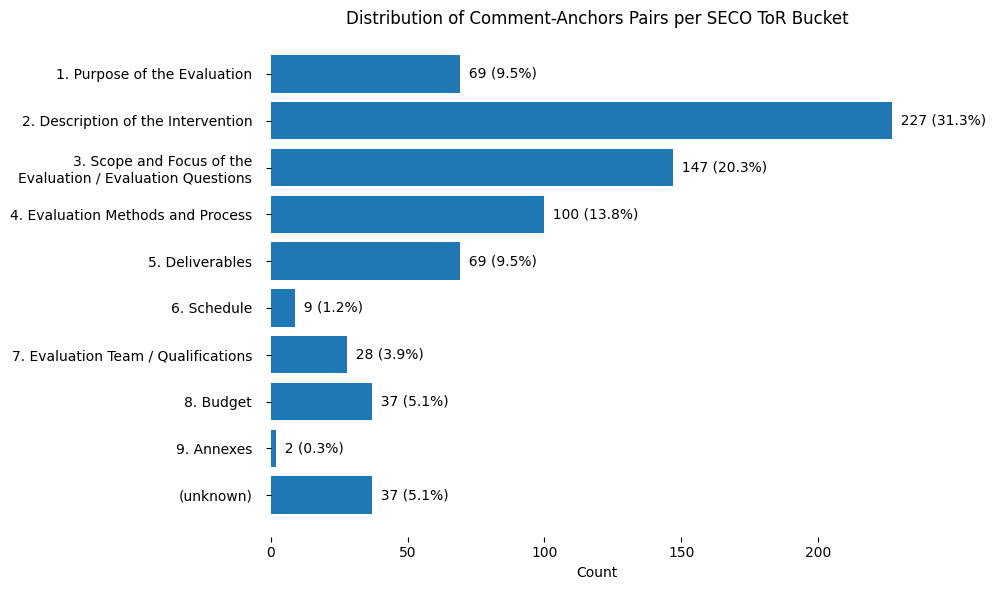

In [ ]:
# Cell 2.9 — Visualize bucket distribution as a clean horizontal bar chart

# Create figure with defined size
plt.figure(figsize=(10, 6))

# Plot horizontal bars for bucket counts
bars = plt.barh(wrapped_labels, bucket_counts)

# Label x-axis and set chart title
plt.xlabel("Count")
plt.title("Distribution of Comment-Anchors Pairs per SECO ToR Bucket")

# Access current axes to adjust formatting
ax = plt.gca()

# Right-align y-axis labels and add spacing
ax.set_yticklabels(wrapped_labels, ha="right")
ax.tick_params(axis='y', pad=10)

# Remove outer frame (all spines) for a cleaner look
for spine in ax.spines.values():
    spine.set_visible(False)

# Invert y-axis so section 1 appears at the top
ax.invert_yaxis()

# Add count and percentage labels at the end of each bar
for i, (count, pct) in enumerate(zip(bucket_counts, bucket_percent)):
    plt.text(
        count,
        i,
        f"  {count} ({pct:.1f}%)",
        va="center"
    )

# Optimize layout to prevent overlap
plt.tight_layout()

# Display the plot
plt.show()

## 3 Generating section-specific checklist items

In [ ]:
# Cell 3.1 — Load env + input data and validate columns

# Load environment variables (e.g., API keys) from the .env file
load_dotenv(ENV_FILE_PATH)

# Load the cleaned comments dataset from CSV
df = pd.read_csv(CLEANED_COMMENTS_CSV_PATH)

# Remove potential leading/trailing whitespace from column names
df.columns = [c.strip() for c in df.columns]

# Define required columns needed for further analysis
required = {"bucket", "comment", "anchor_paragraph"}

# Check whether any required columns are missing
missing = required - set(df.columns)
if missing:
    # Stop execution if essential columns are not present
    raise ValueError(f"Missing required columns: {missing}. Available: {sorted(df.columns)}")

# Remove rows where bucket, comment, or anchor text is missing
# Reset index afterward to keep row numbering clean
df = df.dropna(subset=["bucket", "comment", "anchor_paragraph"]).reset_index(drop=True)

# Display final dataset shape (rows, columns)
df.shape

(716, 6)

In [ ]:
# Cell 3.2 — OpenAI client + model configuration

oai = OpenAI(api_key=os.environ["OPENAI_API_KEY"])
MODEL = "gpt-5.2"

In [ ]:
# Cell 3.3 — Standardizes sections and prepares sampled, compact evidence for AI processing.

# Parameter settings controlling sampling size and text limits for AI input
TARGET_ITEMS_PER_SECTION = 10          # Target checklist items to generate per section
MAX_EVIDENCE_PER_SECTION = 100         # Maximum comment-anchor pairs sampled per section
MAX_CHARS_ANCHOR = 1000                # Maximum characters kept from anchor text
MAX_CHARS_COMMENT = 1000               # Maximum characters kept from comment text
RANDOM_STATE = 7                       # Fixed seed for reproducible sampling

# Ensure bucket column is clean and consistently formatted
df["bucket"] = df["bucket"].astype(str).str.strip()

# Normalize section labels so similar chapter formats are grouped consistently
def normalize_section(x: str) -> str:
    s = re.sub(r"\s+", " ", str(x)).strip()  # Remove extra whitespace

    # Match leading chapter number and title
    m = re.match(r"^\s*(\d+)\s*[\.\: -]\s*(.+)$", s)
    if not m:
        return "Overarching"  # If no chapter number, classify as overarching

    ch = int(m.group(1))      # Extract chapter number
    title = m.group(2).strip()

    # Standardize formatting of title
    title = re.sub(r"\s*&\s*", " and ", title)     # Replace "&" with "and"
    title = re.sub(r"\s*[/\-]\s*", " ", title)     # Replace separators with space
    title = re.sub(r"\s+", " ", title)             # Clean whitespace

    return f"{ch}. {title}"

# Create canonical section column used for grouping
df["section"] = df["bucket"].map(normalize_section)

# Remove duplicate section-comment-anchor combinations
df = df.drop_duplicates(
    subset=["section", "comment", "anchor_paragraph"]
).reset_index(drop=True)

# Compact and anonymize text before sending to AI
def _compact(text: str, max_chars: int) -> str:
    s = re.sub(r"\s+", " ", str(text)).strip()
    s = re.sub(r"https?://\S+|www\.\S+", "<URL>", s)     # Replace URLs
    s = re.sub(r"\b[\w\.-]+@[\w\.-]+\.\w+\b", "<EMAIL>", s)  # Replace emails
    s = re.sub(r"\b(19|20)\d{2}\b", "<YEAR>", s)         # Replace years
    s = re.sub(r"\b\d{3,}\b", "<NUM>", s)                # Replace large numbers
    return s[:max_chars]  # Enforce character limit

# Build structured evidence per section (with optional sampling)
def build_evidence(section_df: pd.DataFrame) -> tuple[list[str], int, int]:
    total_n = len(section_df)  # Total rows in this section
    sample_n = min(total_n, MAX_EVIDENCE_PER_SECTION)

    # Randomly sample if section is large
    sample = (
        section_df.sample(sample_n, random_state=RANDOM_STATE)
        if total_n > sample_n
        else section_df
    )

    lines = []
    for i, r in enumerate(sample.itertuples(index=False), start=1):
        a = _compact(r.anchor_paragraph, MAX_CHARS_ANCHOR)
        c = _compact(r.comment, MAX_CHARS_COMMENT)
        lines.append(f"{i}. anchor: {a} | comment: {c}")

    return lines, total_n, sample_n

# Sort sections numerically and place "Overarching" at the end
sections = sorted(
    df["section"].unique(),
    key=lambda s: (999 if s == "Overarching" else int(s.split(".")[0]), s)
)

len(sections), df.shape  # Show number of sections and final dataset size

Sections containing '4.': ['4. Evaluation Methods and Process']


(10, (695, 7))

In [ ]:
# Cell 3.4 — Structured output schema + one-call checklist generator (generic, reusable items)

# Define the structure of a single checklist item returned by the model
class ChecklistItem(BaseModel):
    requirement: str = Field(..., description="Reusable ToR requirement; generic; no doc-specific details.")
    fail_signal: str = Field(..., description="Observable sign in a ToR that requirement is not met.")
    fix_pattern: str = Field(..., description="Concrete edit/template to fix the ToR.")
    priority: Literal["High", "Medium", "Low"]  # Importance level of the requirement
    evidence_ids: List[int] = Field(default_factory=list, description="Evidence line numbers (from the provided list).")

# Define the overall structured output containing multiple checklist items
class ChecklistOut(BaseModel):
    items: List[ChecklistItem]

# System instruction guiding the model's behavior and output constraints
SYSTEM = """You convert reviewer comments on evaluation Terms of Reference (ToR) into a reusable checklist.

Rules:
- Output MUST be reusable across new ToRs (not tied to one document).
- Avoid organization/project names, countries, dates, budgets, and other specifics. Use placeholders like [AGENCY], [PROGRAM], [COUNTRY], [YEAR], [BUDGET], [DELIVERABLE].
- Each item MUST be relevant to the provided SECTION.
- Only produce "Overarching" items when SECTION is Overarching.
- Requirements must be checkable by reading a ToR (clear pass/fail).
- Merge duplicates. Prefer high-impact, recurring issues.
- Keep each field concise and action-oriented.
- evidence_ids must refer only to the provided evidence line numbers.
"""

# Generate checklist items for a specific section using structured model output
def generate_checklist_for_section(section: str, evidence_lines: list[str], n_items: int = TARGET_ITEMS_PER_SECTION) -> ChecklistOut:

    # Build the user prompt including section name and formatted evidence
    prompt = (
        f"SECTION: {section}\n\n"
        f"EVIDENCE (line_number | anchor | comment):\n" + "\n".join(evidence_lines) + "\n\n"
        f"Task: Return EXACTLY {n_items} reusable checklist items for improving NEW ToRs in this SECTION.\n"
        f"- If evidence is repetitive, generalize to reach {n_items} items (do not return fewer).\n"
        f"- Do NOT quote evidence verbatim; abstract it.\n"
    )

    # Preferred path: directly parse structured output into ChecklistOut
    if hasattr(oai.responses, "parse"):
        resp = oai.responses.parse(
            model=MODEL,
            input=[
                {"role": "system", "content": SYSTEM},
                {"role": "user", "content": prompt},
            ],
            text_format=ChecklistOut,      # Enforce structured schema
            temperature=0.2,               # Low temperature for consistency
            max_output_tokens=1400,        # Limit output size
        )
        return resp.output_parsed         # Return validated structured object

    # Fallback path: manually enforce JSON schema formatting
    schema = ChecklistOut.model_json_schema()
    resp = oai.responses.create(
        model=MODEL,
        input=[
            {"role": "system", "content": SYSTEM},
            {"role": "user", "content": prompt},
        ],
        text={
            "format": {
                "type": "json_schema",
                "name": "checklist",
                "strict": True,           # Enforce strict schema compliance
                "schema": schema,
            }
        },
        temperature=0.2,
        max_output_tokens=1400,
    )

    # Validate and convert JSON response into ChecklistOut object
    return ChecklistOut.model_validate_json(resp.output_text)

In [ ]:
# Cell 3.5 — Build checklist for every section (with basic validation + dedupe)

# Define priority ranking for sorting (High first)
priority_rank = {"High": 0, "Medium": 1, "Low": 2}

rows = []     # Final checklist items across all sections
errors = {}   # Store sections that fail during generation

# Loop through each normalized section
for s in sections:
    sec_df = df[df["section"] == s]  # Filter data for this section
    evidence_lines, total_n, sample_n = build_evidence(sec_df)  # Build sampled evidence

    # Internal function to generate and clean checklist items
    def _run(e_lines, _sample_n):
        out = generate_checklist_for_section(s, e_lines)  # Call AI model
        items = out.items

        cleaned = []
        seen = set()  # Track duplicate requirements

        # Clean and deduplicate items
        for it in items:
            req = re.sub(r"\s+", " ", it.requirement).strip()
            key = req.lower()
            if not req or key in seen:
                continue  # Skip empty or duplicate requirements
            seen.add(key)

            # Validate and clean evidence IDs
            ev = []
            for x in it.evidence_ids:
                if isinstance(x, int):
                    ev.append(x)
                elif isinstance(x, str) and x.strip().isdigit():
                    ev.append(int(x.strip()))
            ev = [x for x in ev if 1 <= x <= _sample_n]

            # Estimate evidence frequency relative to full section size
            ev_count_est = int(round(len(ev) * (total_n / max(_sample_n, 1))))

            # Store cleaned checklist item
            cleaned.append({
                "section": s,
                "requirement": req,
                "fail_signal": re.sub(r"\s+", " ", it.fail_signal).strip(),
                "fix_pattern": re.sub(r"\s+", " ", it.fix_pattern).strip(),
                "priority": it.priority,
                "evidence_count": ev_count_est,
            })

        # Sort by priority first, then by estimated evidence frequency (descending)
        cleaned.sort(key=lambda r: (priority_rank.get(r["priority"], 9), -r["evidence_count"]))

        # Keep only the target number of items per section
        return cleaned[:TARGET_ITEMS_PER_SECTION]

    try:
        cleaned = _run(evidence_lines, sample_n)

        # Retry once if no usable items were generated
        if len(cleaned) == 0:
            cleaned = _run(evidence_lines[:30], min(sample_n, 30))

        rows.extend(cleaned)

    except Exception as e:
        # Retry with smaller evidence to reduce prompt or parsing failure risk
        try:
            cleaned = _run(evidence_lines[:30], min(sample_n, 30))
            rows.extend(cleaned)
        except Exception as e2:
            # Log persistent errors for later inspection
            errors[s] = f"{type(e).__name__}: {str(e)[:200]} | retry -> {type(e2).__name__}: {str(e2)[:200]}"

# Output total generated checklist rows and number of sections with errors
len(rows), len(errors)

(100, 0)

In [ ]:
# Cell 3.6 — Final dataframe in required format + save

# Convert collected checklist rows into a dataframe
checklist_df = pd.DataFrame(rows)

# Keep only the required output columns in the correct order
checklist_df = checklist_df[[
    "section", "requirement", "fail_signal", "fix_pattern", "priority", "evidence_count"
]]

# Create temporary numeric ranking for priority (High → Low)
checklist_df["priority_rank"] = checklist_df["priority"].map(priority_rank).fillna(9).astype(int)

# Sort by section, then priority, then evidence frequency (descending)
checklist_df = checklist_df.sort_values(
    ["section", "priority_rank", "evidence_count"],
    ascending=[True, True, False]
)

# Remove helper ranking column and reset index
checklist_df = checklist_df.drop(columns=["priority_rank"]).reset_index(drop=True)

# Ensure output directory exists
os.makedirs(CHECKLIST_OUT_DIR, exist_ok=True)

# Save final checklist to CSV
checklist_df.to_csv(CHECKLIST_OUT_PATH, index=False)

# Return path of saved file
CHECKLIST_OUT_PATH

'/content/drive/MyDrive/HSLU/Masters_Thesis/Checklist_Documents/tor_checklist.csv'

In [ ]:
# Cell 3.7 — Quick quality check on which sections failed, and section coverage

# Check whether any sections failed during checklist generation
if errors:
    print("Sections with errors:", len(errors))
    for k, v in list(errors.items())[:10]:
        print("-", k, "->", v[:200], "...")  # Show first part of each error message
else:
    print("No section-level errors.")

# Show number of checklist items generated per section (sorted descending)
print(checklist_df.groupby("section").size().sort_values(ascending=False).head(30))

# Display first 20 checklist items for Chapter 4 as a quick inspection
print("\nChapter 4 items:")
print(checklist_df[checklist_df["section"].str.startswith("4.")].head(20))


No section-level errors.
section
1. Purpose of the Evaluation                                 10
2. Description of the Intervention                           10
3. Scope and Focus of the Evaluation Evaluation Questions    10
4. Evaluation Methods and Process                            10
5. Deliverables                                              10
6. Schedule                                                  10
7. Evaluation Team Qualifications                            10
8. Budget                                                    10
9. Annexes                                                   10
Overarching                                                  10
dtype: int64

Chapter 4 items:
                              section  \
30  4. Evaluation Methods and Process   
31  4. Evaluation Methods and Process   
32  4. Evaluation Methods and Process   
33  4. Evaluation Methods and Process   
34  4. Evaluation Methods and Process   
35  4. Evaluation Methods and Process   
36  4. Ev